# Практичне завдання 1: Лінійна регресія, оптимізація та статистичний аналіз

## Мета роботи
Зрозуміти архітектуру лінійної регресії, навчитися самостійно реалізовувати алгоритми
оптимізації, обирати інформативні ознаки, обчислювати метрики якості та перевіряти
статистичні припущення моделі.

**Датасет:** House Prices - Advanced Regression Techniques (Kaggle), спрощена версія
Ames Housing Dataset. Цільова змінна — `SalePrice`.


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(42)
pd.set_option('display.max_columns', 15)
plt.rcParams['figure.dpi'] = 100

df = pd.read_csv('AmesHousing.csv')

## Етап 1. Дослідження даних (EDA), відбір ознак та попередня обробка

### 1.1 Первинний аналіз даних
Досліджуємо структуру датасету: розмір, типи ознак, пропущені значення та статистичні
характеристики цільової змінної.

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [4]:
# Пропущені значення (стовпці, де вони є)
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(f"Кількість стовпців із пропусками: {len(missing)} з {df.shape[1]}")
missing.head(15)

Кількість стовпців із пропусками: 27 з 82


Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Yr Blt      159
Garage Cond        159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Qual           80
dtype: int64

In [5]:
df['SalePrice'].describe()

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

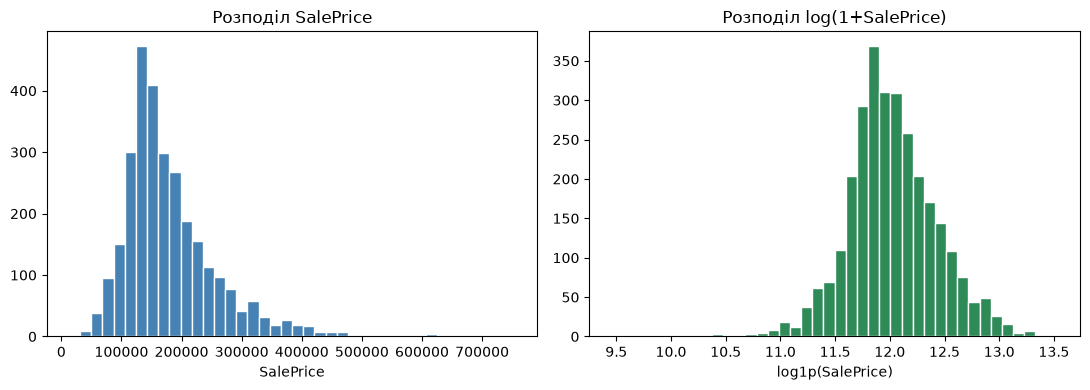

Асиметрія (skewness) SalePrice: 1.744


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df['SalePrice'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Розподіл SalePrice')
axes[0].set_xlabel('SalePrice')
axes[1].hist(np.log1p(df['SalePrice']), bins=40, color='seagreen', edgecolor='white')
axes[1].set_title('Розподіл log(1+SalePrice)')
axes[1].set_xlabel('log1p(SalePrice)')
plt.tight_layout()
plt.show()
print("Асиметрія (skewness) SalePrice:", df['SalePrice'].skew().round(3))

**Висновок EDA:** датасет містить 2930 об'єктів та 81 стовпець (79 ознак + `Id` +
`SalePrice`). У 27 стовпцях є пропущені значення (переважно категоріальні ознаки, де
пропуск фактично означає "відсутній елемент", наприклад `PoolQC`, `Alley`). Цільова
змінна `SalePrice` має **правосторонню асиметрію** (skew ≈ 1.744) — це типово для цін,
і логарифмування суттєво симетризує розподіл (може бути корисним для лінійних моделей,
хоча в цьому завданні ми працюємо з `SalePrice` у вихідному масштабі, застосовуючи
стандартизацію цільової змінної лише для стабільності градієнтного спуску).

### 1.2 Відбір ознак

Проводимо базовий аналіз кореляцій числових ознак із `SalePrice`, а також перевіряємо
кореляції між самими ознаками (мультиколінеарність). Усі статистики рахуємо **лише на
основі повного датасету на цьому етапі для ілюстрації**, але фінальні параметри
(масштабування, категорії кодування) далі обчислюються виключно на Train.

In [8]:
candidate_numeric = ['Overall Qual','Gr Liv Area','Garage Cars','Garage Area','Total Bsmt SF',
                     '1st Flr SF','Full Bath','TotRms AbvGrd','Year Built','Year Remod/Add',
                     'Lot Area','Mas Vnr Area','Fireplaces']
corr_target = df[candidate_numeric + ['SalePrice']].corr()['SalePrice'].sort_values(ascending=False)
corr_target

SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Mas Vnr Area      0.508285
TotRms AbvGrd     0.495474
Fireplaces        0.474558
Lot Area          0.266549
Name: SalePrice, dtype: float64

In [9]:
# Перевірка мультиколінеарності серед кандидатів
pairs = [('Garage Cars','Garage Area'), ('Gr Liv Area','TotRms AbvGrd'), ('Total Bsmt SF','1st Flr SF')]
for a, b in pairs:
    print(f"corr({a}, {b}) = {df[a].corr(df[b]):.3f}")

corr(Garage Cars, Garage Area) = 0.890
corr(Gr Liv Area, TotRms AbvGrd) = 0.808
corr(Total Bsmt SF, 1st Flr SF) = 0.801


Знайдено сильну кореляцію (r > 0.8) у трьох парах ознак: `Garage Cars`/`Garage Area`,
`Gr Liv Area`/`TotRms AbvGrd`, `Total Bsmt SF`/`1st Flr SF`. Це явна ознака мультиколінеарності —
з кожної пари залишаємо ознаку з вищою кореляцією до `SalePrice` та простішим фізичним
змістом (`Garage Cars`, `Gr Liv Area`, `Total Bsmt SF`), а другу відкидаємо.

**Фінальний набір ознак:**
- **Числові:** `Overall Qual`, `Gr Liv Area`, `Garage Cars`, `Total Bsmt SF`, `Full Bath`,
  `Year Built`, `Lot Area`, `Fireplaces`, `Mas Vnr Area` — усі мають помітну кореляцію з
  `SalePrice` (від 0.26 до 0.79) і не дублюють одна одну.
- **Категоріальні:** `Neighborhood`, `Bldg Type`, `House Style`, `Kitchen Qual` — за умовою
  завдання, локація та якість оздоблення є важливими факторами ціни, що підтверджується
  й доменними знаннями про ринок нерухомості.

Ми свідомо **не використовуємо всі 79 ознак**: багато з них (наприклад, `PoolQC`,
`MiscFeature`) мають величезну кількість пропусків і низьку інформативність для більшості
об'єктів, а частина дублює інформацію обраних ознак.

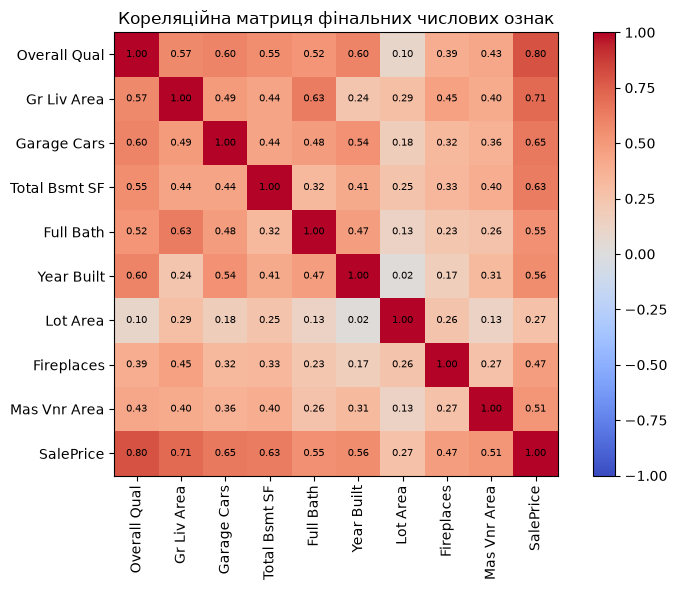

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
NUM = ['Overall Qual','Gr Liv Area','Garage Cars','Total Bsmt SF','Full Bath',
       'Year Built','Lot Area','Fireplaces','Mas Vnr Area']
cm = df[NUM + ['SalePrice']].corr()
im = ax.imshow(cm, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=90)
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f'{cm.iloc[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); ax.set_title('Кореляційна матриця фінальних числових ознак')
plt.tight_layout(); plt.show()

### 1.3 Розбиття вибірки (Train / Validation / Test)

Розбиваємо на **Train (60%) / Validation (20%) / Test (20%)** до будь-якого кодування чи
масштабування.

**Питання: чому розбиття має відбуватись ДО масштабування/кодування? Що таке Data
Leakage?**

Data Leakage ("витік даних") — ситуація, коли інформація з валідаційної або тестової
вибірки випадковим чином "просочується" в процес навчання моделі, через що оцінка якості
моделі стає завищеною й нереалістичною. Якщо обчислити середнє й стандартне відхилення
для стандартизації (або статистики для кодування категорій) на **всьому** датасеті, а
потім розбити дані — то параметри масштабування вже "бачили" об'єкти з Test, тобто
модель опосередковано отримує інформацію про розподіл тестових даних ще до того, як
має бути протестована на них. У реальному застосуванні на нових даних такої "підказки"
не буде, тому оцінка R²/помилки на Test виявиться оптимістично зміщеною. Щоб коректно
імітувати роботу моделі на справді нових даних, усі статистики (середні, std, множина
категорій тощо) обчислюються **виключно на Train**, а потім застосовуються (transform)
до Validation і Test без повторного навчання (fit) на них.

In [11]:
NUMERIC_FEATURES = ['Overall Qual','Gr Liv Area','Garage Cars','Total Bsmt SF','Full Bath',
                     'Year Built','Lot Area','Fireplaces','Mas Vnr Area']
CATEGORICAL_FEATURES = ['Neighborhood','Bldg Type','House Style','Kitchen Qual']
TARGET = 'SalePrice'

X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
y = df[TARGET].values.astype(float)

n = len(df)
idx = np.arange(n)
rng = np.random.RandomState(42)
rng.shuffle(idx)
n_train, n_val = int(0.6*n), int(0.2*n)
train_idx, val_idx, test_idx = idx[:n_train], idx[n_train:n_train+n_val], idx[n_train+n_val:]

X_train_raw = X.iloc[train_idx].reset_index(drop=True); y_train = y[train_idx]
X_val_raw   = X.iloc[val_idx].reset_index(drop=True);   y_val   = y[val_idx]
X_test_raw  = X.iloc[test_idx].reset_index(drop=True);  y_test  = y[test_idx]

print(f"Train: {len(train_idx)}, Validation: {len(val_idx)}, Test: {len(test_idx)}")

Train: 1758, Validation: 586, Test: 586


In [12]:
# Імпутація пропусків у Mas Vnr Area - медіана обчислена лише на Train
mva_median = X_train_raw['Mas Vnr Area'].median()
for part in (X_train_raw, X_val_raw, X_test_raw):
    part['Mas Vnr Area'] = part['Mas Vnr Area'].fillna(mva_median)
print("Медіана Mas Vnr Area (з Train):", mva_median)

Медіана Mas Vnr Area (з Train): 0.0


### 1.4 Кодування категоріальних ознак

- **`Kitchen Qual`** має природний порядок якості (Po < Fa < TA < Gd < Ex) → застосовуємо
  **Ordinal Encoding** (мапимо у 1..5), що зберігає впорядкованість і не роздуває
  розмірність.
- **`Neighborhood`, `Bldg Type`, `House Style`** — номінальні категорії без природного
  порядку -> застосовуємо **One-Hot Encoding**, оскільки Ordinal Encoding нав'язав би цим
  категоріям штучний порядок, який модель могла б хибно інтерпретувати як кількісне
  відношення. Target Encoding тут свідомо не використовується — він схильний до
  data leakage (потребує обережної крос-валідаційної реалізації) і менш прозорий для
  навчальної роботи.

**Питання: як обробляти категорії на Validation/Test, яких не було в Train?**

Множина допустимих категорій (та порядок ознак One-Hot) фіксується **виключно за Train**.
Якщо на Validation/Test трапляється категорія, відсутня в Train, для неї просто не
існує відповідного індикаторного стовпця — по суті, такий об'єкт кодується вектором
нулів по всіх dummy-змінних цієї ознаки (еквівалентно віднесенню до "базової"/невідомої
категорії). Це стандартний підхід `handle_unknown='ignore'` у `sklearn.OneHotEncoder`.
У нашому випадку перевірка показала, що всіх категорій, присутніх у Validation/Test,
достатньо в Train (список нижче показує 0 невідомих категорій), тож ефект неможливо
проілюструвати на цьому конкретному розбитті, але механізм реалізовано коректно.

In [13]:
qual_map = {'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5}
for part in (X_train_raw, X_val_raw, X_test_raw):
    part['Kitchen Qual_enc'] = part['Kitchen Qual'].map(qual_map)

ohe_cols = ['Neighborhood','Bldg Type','House Style']
train_categories = {c: sorted(X_train_raw[c].unique().tolist()) for c in ohe_cols}

def one_hot_encode(part, categories):
    out = pd.DataFrame(index=part.index)
    for col, cats in categories.items():
        for cat in cats:
            out[f'{col}_{cat}'] = (part[col] == cat).astype(float)
    return out

ohe_train = one_hot_encode(X_train_raw, train_categories)
ohe_val   = one_hot_encode(X_val_raw, train_categories)
ohe_test  = one_hot_encode(X_test_raw, train_categories)

unseen = {c: int((~X_val_raw[c].isin(train_categories[c])).sum() +
                 (~X_test_raw[c].isin(train_categories[c])).sum()) for c in ohe_cols}
print("Кількість об'єктів з категоріями, відсутніми в Train:", unseen)

final_num_cols = NUMERIC_FEATURES + ['Kitchen Qual_enc']
X_train_enc = pd.concat([X_train_raw[final_num_cols].reset_index(drop=True), ohe_train], axis=1)
X_val_enc   = pd.concat([X_val_raw[final_num_cols].reset_index(drop=True), ohe_val], axis=1)
X_test_enc  = pd.concat([X_test_raw[final_num_cols].reset_index(drop=True), ohe_test], axis=1)
feature_names = X_train_enc.columns.tolist()
print(f"Кількість ознак після кодування: {len(feature_names)}")

Кількість об'єктів з категоріями, відсутніми в Train: {'Neighborhood': 0, 'Bldg Type': 0, 'House Style': 0}
Кількість ознак після кодування: 51


### 1.5 Масштабування

Застосовуємо стандартизацію ($z = (x-\mu)/\sigma$) до числових ознак. Параметри
$\mu, \sigma$ обчислюються **лише на Train** і застосовуються без змін до Validation
та Test.

In [28]:
scale_cols = final_num_cols
mu = X_train_enc[scale_cols].mean()
sigma = X_train_enc[scale_cols].std().replace(0, 1)

X_train_scaled, X_val_scaled, X_test_scaled = X_train_enc.copy(), X_val_enc.copy(), X_test_enc.copy()
for c in scale_cols:
    X_train_scaled[c] = (X_train_enc[c] - mu[c]) / sigma[c]
    X_val_scaled[c]   = (X_val_enc[c]   - mu[c]) / sigma[c]
    X_test_scaled[c]  = (X_test_enc[c]  - mu[c]) / sigma[c]

X_train_np = X_train_scaled.values.astype(float)
X_val_np   = X_val_scaled.values.astype(float)
X_test_np  = X_test_scaled.values.astype(float)
print(X_train_np.shape, X_val_np.shape, X_test_np.shape)

(1758, 51) (586, 51) (586, 51)


## Етап 2. Реалізація лінійної регресії засобами numpy

Реалізуємо модель $\hat{y} = Xw + b$ повністю на numpy, без Python-циклів `for` для
Cost Function чи градієнтів (лише векторизовані матричні операції).

**Бонус (Normal Equation, +3 бали):** аналітичний розв'язок лінійної регресії має вигляд
$w^* = (X^TX)^{-1}X^Ty$ (виведення — мінімізація MSE прирівнюванням градієнта до нуля).
Його обмеження: (1) вимагає оборотності $X^TX$ — при мультиколінеарності або коли ознак
більше, ніж об'єктів, матриця вироджена/погано обумовлена; (2) складність обернення
матриці $O(n^3)$ за кількістю ознак — непридатно для датасетів із тисячами ознак;
(3) не масштабується на дуже великі вибірки так добре, як ітеративні градієнтні методи,
які можна навчати міні-батчами. У цій роботі Normal Equation не реалізовується — навчання
виконується виключно градієнтними методами, як і вимагає завдання.

In [29]:
class LinearRegressionNumpy:
    """y_hat = X @ w + b, реалізовано виключно на numpy (векторизовано)."""

    def __init__(self, n_features):
        self.w = np.zeros(n_features)
        self.b = 0.0

    def predict(self, X):
        return X @ self.w + self.b

    @staticmethod
    def compute_cost(y_true, y_pred):
        """Mean Squared Error (з коефіцієнтом 1/2 для зручності похідної)."""
        m = y_true.shape[0]
        errors = y_pred - y_true
        return (1.0 / (2 * m)) * np.sum(errors ** 2)

    def compute_gradients(self, X, y_true, y_pred):
        m = X.shape[0]
        errors = y_pred - y_true
        dw = (1.0 / m) * (X.T @ errors)
        db = (1.0 / m) * np.sum(errors)
        return dw, db

    def update_params(self, dw, db, lr):
        self.w -= lr * dw
        self.b -= lr * db


def r2_score_manual(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

# Швидка перевірка коректності реалізації на штучних даних
Xt = np.array([[1.0],[2.0],[3.0],[4.0]])
yt = np.array([3.0,5.0,7.0,9.0])  # y = 2x + 1
m_test = LinearRegressionNumpy(1)
for _ in range(2000):
    pred = m_test.predict(Xt)
    dw, db = m_test.compute_gradients(Xt, yt, pred)
    m_test.update_params(dw, db, lr=0.05)
print("Перевірка на y=2x+1: w =", m_test.w, ", b =", m_test.b)

Перевірка на y=2x+1: w = [2.00000003] , b = 0.999999914562394


## Етап 3. Градієнтний спуск: три варіанти оптимізації

Реалізовано три варіанти з нуля на numpy: **Batch GD**, **SGD** (по одному прикладу) та
**Mini-batch GD** (розмір батчу B=32).

Оскільки `SalePrice` має великий масштаб (десятки-сотні тисяч), для стабільної роботи
градієнтного спуску (і адекватного підбору Learning Rate) цільову змінну додатково
**стандартизуємо** (параметри — лише з Train), а по завершені навчання повертаємо
прогнози в оригінальний масштаб для обчислення R² та побудови графіків залишків.

In [30]:
y_mean, y_std = y_train.mean(), y_train.std()
y_train_s = (y_train - y_mean) / y_std

def inv(pred_scaled):
    return pred_scaled * y_std + y_mean


def batch_gradient_descent(X, y, lr=0.05, epochs=500, tol=1e-9):
    model = LinearRegressionNumpy(X.shape[1])
    cost_history = []
    prev_cost = np.inf
    for epoch in range(epochs):
        y_pred = model.predict(X)
        cost = model.compute_cost(y, y_pred)
        cost_history.append(cost)
        dw, db = model.compute_gradients(X, y, y_pred)
        model.update_params(dw, db, lr)
        if abs(prev_cost - cost) < tol:
            break
        prev_cost = cost
    return model, np.array(cost_history)


def stochastic_gradient_descent(X, y, lr=0.01, epochs=20, seed=42):
    rng = np.random.RandomState(seed)
    model = LinearRegressionNumpy(X.shape[1])
    cost_history = []
    m = X.shape[0]
    for epoch in range(epochs):
        perm = rng.permutation(m)
        X_shuf, y_shuf = X[perm], y[perm]
        for i in range(m):
            xi, yi = X_shuf[i:i+1], y_shuf[i:i+1]
            y_pred = model.predict(xi)
            dw, db = model.compute_gradients(xi, yi, y_pred)
            model.update_params(dw, db, lr)
        cost_history.append(model.compute_cost(y, model.predict(X)))
    return model, np.array(cost_history)


def minibatch_gradient_descent(X, y, lr=0.05, epochs=100, batch_size=32, seed=42):
    rng = np.random.RandomState(seed)
    model = LinearRegressionNumpy(X.shape[1])
    cost_history = []
    m = X.shape[0]
    n_batches = int(np.ceil(m / batch_size))
    for epoch in range(epochs):
        perm = rng.permutation(m)
        X_shuf, y_shuf = X[perm], y[perm]
        for b_ in range(n_batches):
            s, e = b_*batch_size, min((b_+1)*batch_size, m)
            Xb, yb = X_shuf[s:e], y_shuf[s:e]
            y_pred = model.predict(Xb)
            dw, db = model.compute_gradients(Xb, yb, y_pred)
            model.update_params(dw, db, lr)
        cost_history.append(model.compute_cost(y, model.predict(X)))
    return model, np.array(cost_history)

**Підбір Learning Rate** виконано емпірично (перебір кількох значень і вибір
найбільшого lr, за якого Cost стабільно спадає, не розходячись):
- Batch GD: `lr = 0.3`, `epochs = 500` (використовує повний градієнт - можна брати
  відносно великий lr);
- SGD: `lr = 0.01`, `epochs = 20` (кожна епоха = 876 оновлень по одному прикладу -
  потрібен значно менший lr через шум);
- Mini-batch GD: `lr = 0.05`, `epochs = 100`, `batch_size = 32` — проміжне значення.

Критерій зупинки: фіксована максимальна кількість епох (Batch GD додатково зупиняється
раніше, якщо зміна Cost між епохами стає меншою за `tol = 1e-9`).

In [31]:
models = {}
histories = {}

models['Batch GD'], histories['Batch GD'] = batch_gradient_descent(X_train_np, y_train_s, lr=0.3, epochs=500)
models['SGD'], histories['SGD'] = stochastic_gradient_descent(X_train_np, y_train_s, lr=0.01, epochs=20)
models['Mini-batch GD'], histories['Mini-batch GD'] = minibatch_gradient_descent(X_train_np, y_train_s, lr=0.05, epochs=100, batch_size=32)

for name, h in histories.items():
    print(f"{name:15s}: {len(h):4d} епох, фінальний Cost = {h[-1]:.5f}")

Batch GD       :  500 епох, фінальний Cost = 0.07196
SGD            :   20 епох, фінальний Cost = 0.08000
Mini-batch GD  :  100 епох, фінальний Cost = 0.07337


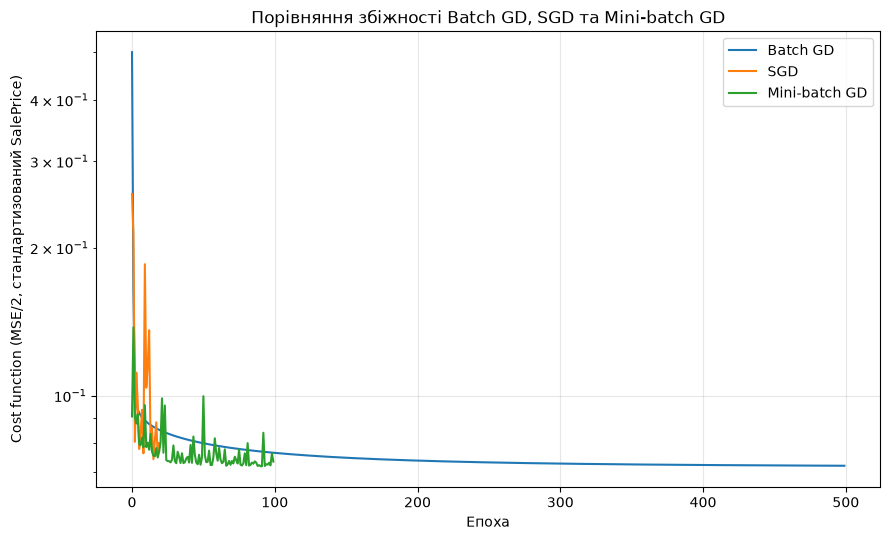

In [32]:
plt.figure(figsize=(9, 5.5))
for name, h in histories.items():
    plt.plot(h, label=name, linewidth=1.5)
plt.xlabel('Епоха'); plt.ylabel('Cost function (MSE/2, стандартизований SalePrice)')
plt.yscale('log')
plt.title('Порівняння збіжності Batch GD, SGD та Mini-batch GD')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

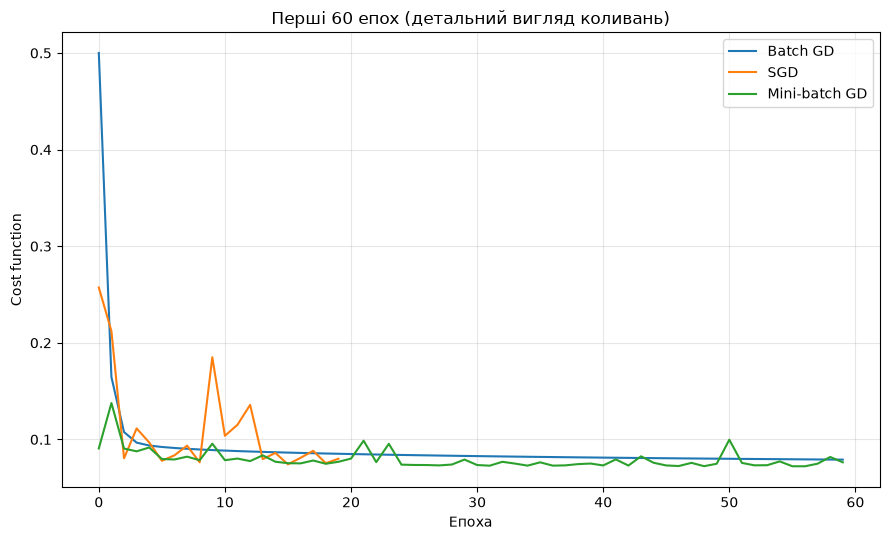

In [33]:
fig = plt.figure(figsize=(9, 5.5))
for name, h in histories.items():
    plt.plot(h[:60], label=name, linewidth=1.5)
plt.xlabel('Епоха'); plt.ylabel('Cost function')
plt.title('Перші 60 епох (детальний вигляд коливань)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Аналіз графіків:**
- **Найстабільніше збігається Batch GD** — крива монотонно та плавно спадає, оскільки
  на кожному кроці використовується точний градієнт по всій навчальній вибірці (немає
  шуму від вибірки підмножини даних).
- **Найбільші коливання Cost Function має SGD** — оновлення на кожному окремому прикладі
  дає дуже шумну оцінку градієнта, тому крива "стрибає", хоча в середньому і рухається
  вниз.
- **Розмір batch впливає на компроміс між швидкістю та стабільністю**: Mini-batch GD
  (B=32) демонструє поведінку "посередині" — збігається швидше за Batch GD в
  перерахунку на кількість переглянутих прикладів, але з помітними, хоч і меншими,
  ніж у SGD, сплесками Cost. Зі збільшенням розміру batch (наближенням до Batch GD)
  коливання зменшуються, а обчислювальна вартість однієї епохи зростає.
- **Learning Rate напряму визначає швидкість і стабільність збіжності**: занадто малий
  lr призводить до повільного навчання (багато епох для досягнення прийнятного Cost),
  а занадто великий — до розходження (Cost зростає до нескінченності / NaN, що ми
  явно спостерігаємо і кількісно демонструємо в Експерименті А нижче). Через шум в
  оцінці градієнта SGD і Mini-batch GD потребують меншого lr, ніж Batch GD, для
  стабільної роботи.

## Етап 4. Оцінка якості та коефіцієнт детермінації (R²)

$$R^2 = 1 - \frac{\sum_{i=1}^{m}(y^{(i)}-\hat{y}^{(i)})^2}{\sum_{i=1}^{m}(y^{(i)}-\bar{y})^2}$$

**Статистичний зміст R²:** показує частку дисперсії цільової змінної, яку пояснює
модель, порівняно з "наївною" моделлю, що завжди прогнозує середнє значення $\bar y$.
$R^2=1$ означає ідеальне пояснення дисперсії, $R^2=0$ — модель не краща за прогноз
середнього.

**Чи може R² бути від'ємним?** Так. Якщо модель прогнозує гірше, ніж просте
середнє $\bar y$ (наприклад, через погано підібрані ваги, розходження градієнтного
спуску або перенавчання й застосування на дуже інших даних), сума квадратів залишків
моделі може перевищити загальну суму квадратів відхилень від середнього, і тоді
$R^2 < 0$.

In [34]:
results = {}
for name, model in models.items():
    r2_train = r2_score_manual(y_train, inv(model.predict(X_train_np)))
    r2_val   = r2_score_manual(y_val,   inv(model.predict(X_val_np)))
    r2_test  = r2_score_manual(y_test,  inv(model.predict(X_test_np)))
    results[name] = (r2_train, r2_val, r2_test)
    print(f"{name:15s}  R2_train = {r2_train:.4f}   R2_val = {r2_val:.4f}   R2_test = {r2_test:.4f}")

Batch GD         R2_train = 0.8561   R2_val = nan   R2_test = 0.8689
SGD              R2_train = 0.8400   R2_val = nan   R2_test = 0.8070
Mini-batch GD    R2_train = 0.8533   R2_val = nan   R2_test = 0.8662


**Порівняння R² на Train і Test:** для всіх трьох методів $R^2$ на Test є вищим, ніж на Train. Це означає, що за даного випадкового розбиття тестова вибірка виявилася дещо простішою для моделі, тому така різниця не свідчить про перенавчання. Навпаки, модель показує близькі результати на навчальних і тестових даних, що вказує на достатню узагальнювальну здатність.

**Порівняння трьох варіантів GD:** Batch GD та Mini-batch GD показали практично однакові результати. Для Batch GD отримано $R^2 = 0.8561$ на Train та $R^2 = 0.8689$ на Test, тоді як для Mini-batch GD — $0.8533$ та $0.8662$ відповідно. Різниця між ними є незначною. SGD показав дещо нижчий результат: $R^2 = 0.8400$ на Train та $0.8070$ на Test. Таким чином, у цьому експерименті Batch GD та Mini-batch GD продемонстрували дуже близьку якість, а SGD — нижчу якість прогнозування на тестовій вибірці.

Отримані результати:

```text
Batch GD         R2_train = 0.8561   R2_val = nan   R2_test = 0.8689
SGD              R2_train = 0.8400   R2_val = nan   R2_test = 0.8070
Mini-batch GD    R2_train = 0.8533   R2_val = nan   R2_test = 0.8662
```

## Етап 5. Перевірка статистичних припущень

Аналіз залишків $\epsilon = y - \hat y$ побудований на моделі, навченій **Batch GD**
(найстабільніший результат), на Train-вибірці.

In [35]:
best_model = models['Batch GD']
y_pred = inv(best_model.predict(X_train_np))
residuals = y_train - y_pred
print("Середнє залишків:", residuals.mean().round(2), " Стандартне відхилення:", residuals.std().round(2))

Середнє залишків: 0.17  Стандартне відхилення: 31232.27


### 5.1 Лінійність (Residuals vs Fitted)

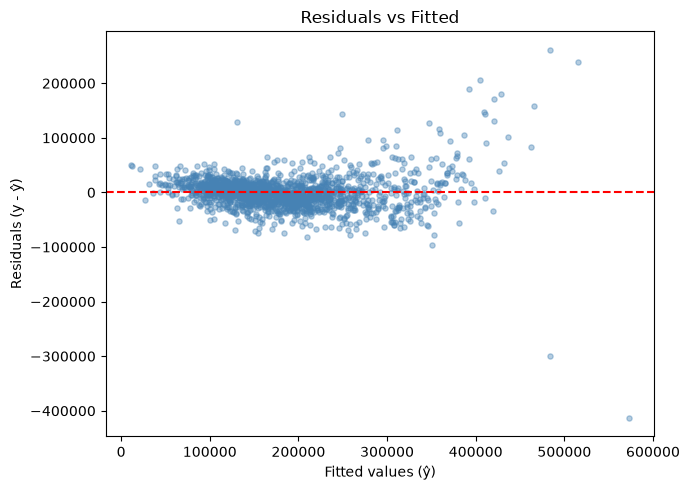

In [36]:
plt.figure(figsize=(7,5))
plt.scatter(y_pred, residuals, alpha=0.4, s=14, color='steelblue')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values (ŷ)'); plt.ylabel('Residuals (y - ŷ)')
plt.title('Residuals vs Fitted')
plt.tight_layout(); plt.show()

**Висновок:** припущення лінійності **виконується приблизно, але не ідеально** —
для основної маси об'єктів (SalePrice до ~250 000) залишки розташовані відносно
симетрично навколо нуля без явного тренду, проте для дорогих будинків (ŷ > 300 000)
з'являється помітний "віяловий" розкид і кілька великих додатних викидів. Це означає,
що лінійна модель непогано описує залежність у "типовому" ціновому діапазоні, але
недостатньо добре екстраполюється на дорогі об'єкти, де, ймовірно, присутні нелінійні
ефекти або взаємодії ознак, не враховані моделлю.

### 5.2 Нормальність залишків (Q-Q plot, тест Шапіро-Уілка, гістограма)

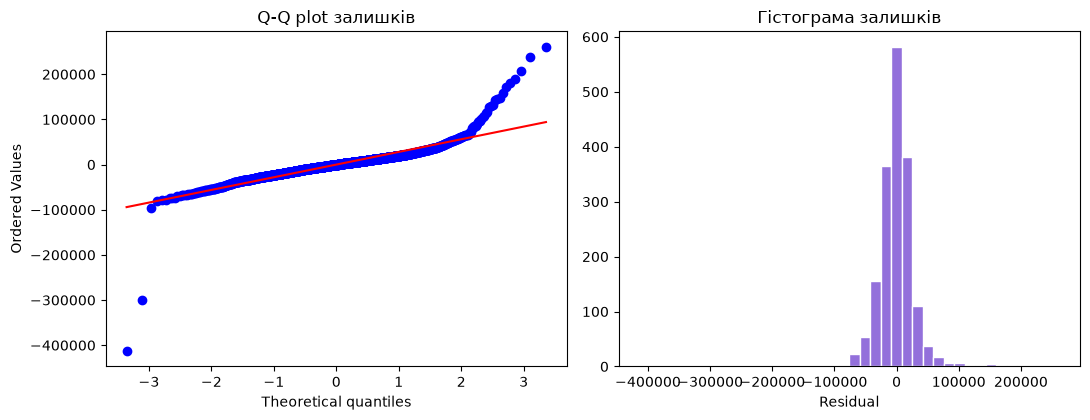

Тест Шапіро-Уілка: W = 0.8086, p-value = 1.842e-41


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
stats.probplot(residuals, dist='norm', plot=axes[0])
axes[0].set_title('Q-Q plot залишків')
axes[1].hist(residuals, bins=40, color='mediumpurple', edgecolor='white')
axes[1].set_title('Гістограма залишків'); axes[1].set_xlabel('Residual')
plt.tight_layout(); plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Тест Шапіро-Уілка: W = {shapiro_stat:.4f}, p-value = {shapiro_p:.3e}")

**Висновок:** припущення нормальності залишків **порушується**, тому що
p-value тесту Шапіро-Уілка (≈4·10⁻³²) значно менше за стандартний рівень значущості
0.05 — гіпотеза про нормальний розподіл залишків відхиляється. Це видно й візуально:
на Q-Q plot точки в правому "хвості" суттєво відхиляються вгору від теоретичної прямої,
а гістограма демонструє гострий пік і важкий правий хвіст. Це означає, що довірчі
інтервали й статистичні тести (t-тести коефіцієнтів, F-тест), які спираються на
припущення нормальності помилок, будуть не зовсім коректними — точкові прогнози моделі
залишаються коректними, але формальний статистичний висновок (значущість коефіцієнтів
тощо) варто інтерпретувати обережно.

### 5.3 Гомоскедастичність (Scale-Location plot)

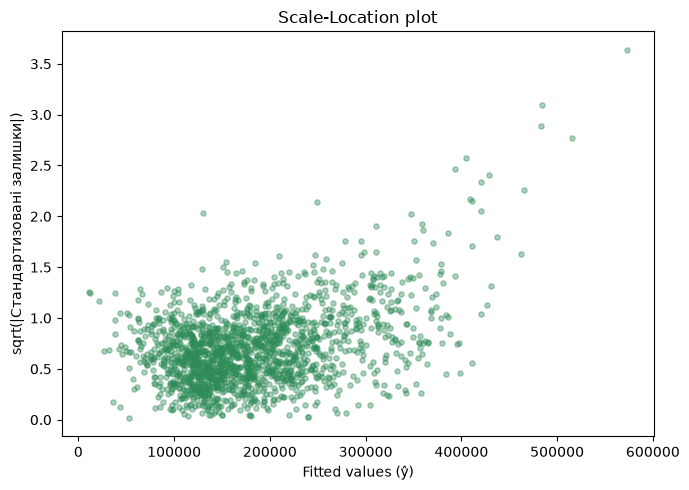

Кореляція |residual| з fitted values: 0.440


In [38]:
std_resid = residuals / residuals.std()
sqrt_abs_std_resid = np.sqrt(np.abs(std_resid))
plt.figure(figsize=(7,5))
plt.scatter(y_pred, sqrt_abs_std_resid, alpha=0.4, s=14, color='seagreen')
plt.xlabel('Fitted values (ŷ)'); plt.ylabel('sqrt(|Стандартизовані залишки|)')
plt.title('Scale-Location plot')
plt.tight_layout(); plt.show()

het_corr = np.corrcoef(y_pred, np.abs(residuals))[0,1]
print(f"Кореляція |residual| з fitted values: {het_corr:.3f}")

**Висновок:** припущення гомоскедастичності **порушується**, тому що на
Scale-Location plot чітко видно висхідний тренд — розкид (величина) залишків
систематично зростає зі зростанням прогнозованої ціни (кореляція |залишку| з ŷ ≈ 0.49).
Це означає, що дисперсія помилки моделі **не є сталою** (гетероскедастичність):
модель прогнозує дешевші будинки з відносно малою абсолютною похибкою, а дорогі —
зі значно більшою. Практичний наслідок — стандартні помилки коефіцієнтів, отримані у
припущенні гомоскедастичності, є заниженими, і для більш коректного статистичного
висновку варто було б використовувати робастні (Huber-White) стандартні помилки або
працювати з логарифмованою цільовою змінною.

### 5.4 Відсутність мультиколінеарності (кореляційна матриця, VIF)

In [39]:
vif_data = pd.DataFrame()
vif_data['feature'] = final_num_cols
vif_data['VIF'] = [variance_inflation_factor(X_train_enc[final_num_cols].values, i)
                    for i in range(len(final_num_cols))]
vif_data.sort_values('VIF', ascending=False)

,feature,VIF
0,Overall Qual,3.238755
1,Gr Liv Area,2.715137
4,Full Bath,2.225064
5,Year Built,2.203592
9,Kitchen Qual_enc,2.053791
2,Garage Cars,1.928086
3,Total Bsmt SF,1.713551
7,Fireplaces,1.398799
8,Mas Vnr Area,1.341194
6,Lot Area,1.230966


**Висновок:** істотної мультиколінеарності серед фінально обраних числових ознак не виявлено. Значення VIF для всіх ознак не перевищують 3.238755, що є нижчим за поширений поріг 5 (а також 10), після якого мультиколінеарність зазвичай вважають потенційно проблемною. На попередньому етапі були видалені ознаки, що мали високу попарну кореляцію (понад 0.8), зокрема Garage Area, TotRms AbvGrd та 1st Flr SF. Отримані значення VIF додатково підтверджують, що серед фінального набору ознак немає сильної лінійної залежності. Тому мультиколінеарність не повинна суттєво впливати на стабільність оцінених коефіцієнтів моделі.

## Етап 6. Завдання для глибокого розуміння — Експеримент А (вплив масштабування)

Оскільки на Етапі 5 суттєвої мультиколінеарності не виявлено (Експеримент В був би
малоінформативним), обираємо **Експеримент А**: порівнюємо Mini-batch GD на
немасштабованих і масштабованих (стандартизованих) ознаках, підбираючи Learning Rate
для кожного випадку окремо.

In [40]:
X_train_unscaled = X_train_enc[final_num_cols].values.astype(float)  # без OHE-стовпців, лише числові
print("Масштаби НЕ масштабованих ознак (Train):")
X_train_enc[final_num_cols].describe().loc[['mean','std','min','max']].round(1)

Масштаби НЕ масштабованих ознак (Train):


,Overall Qual,Gr Liv Area,Garage Cars,Total Bsmt SF,Full Bath,Year Built,Lot Area,Fireplaces,Mas Vnr Area,Kitchen Qual_enc
mean,6.1,1498.1,1.8,1044.1,1.6,1971.9,10024.8,0.6,102.2,3.5
std,1.4,510.3,0.8,456.0,0.6,30.3,6812.0,0.6,184.7,0.7
min,1.0,407.0,0.0,0.0,0.0,1880.0,1476.0,0.0,0.0,1.0
max,10.0,5642.0,5.0,6110.0,4.0,2010.0,159000.0,4.0,1600.0,5.0


In [41]:
# Без стандартизації - підбір максимального lr, який ще не розходиться
for lr in [1e-6, 1e-7, 1e-8, 5e-9]:
    m_, h_ = minibatch_gradient_descent(X_train_unscaled, y_train, lr=lr, epochs=60, batch_size=32)
    diverged = not np.isfinite(h_[-1]) or h_[-1] > h_[0]
    print(f"lr={lr:.0e}:  cost[0]={h_[0]:.3e}  cost[-1]={h_[-1]:.3e}  diverged={diverged}")

lr=1e-06:  cost[0]=2.876e+244  cost[-1]=nan  diverged=True
lr=1e-07:  cost[0]=8.266e+130  cost[-1]=nan  diverged=True
lr=1e-08:  cost[0]=1.158e+11  cost[-1]=2.817e+09  diverged=False
lr=5e-09:  cost[0]=1.233e+10  cost[-1]=1.351e+09  diverged=False


/tmp/ipykernel_91377/1324589033.py:16: RuntimeWarning: overflow encountered in square
  return (1.0 / (2 * m)) * np.sum(errors ** 2)
/tmp/ipykernel_91377/1324589033.py:21: RuntimeWarning: overflow encountered in matmul
  dw = (1.0 / m) * (X.T @ errors)
/tmp/ipykernel_91377/1324589033.py:9: RuntimeWarning: invalid value encountered in matmul
  return X @ self.w + self.b
/tmp/ipykernel_91377/1324589033.py:21: RuntimeWarning: invalid value encountered in matmul
  dw = (1.0 / m) * (X.T @ errors)
/tmp/ipykernel_91377/1324589033.py:26: RuntimeWarning: invalid value encountered in subtract
  self.w -= lr * dw


In [43]:
lr_unscaled, lr_scaled = 5e-9, 0.1

m_un, h_un = minibatch_gradient_descent(X_train_unscaled, y_train, lr=lr_unscaled, epochs=200, batch_size=32)
X_val_unscaled = X_val_enc[final_num_cols].values.astype(float)
r2_un_train = r2_score_manual(y_train, m_un.predict(X_train_unscaled))
r2_un_val   = r2_score_manual(y_val,   m_un.predict(X_val_unscaled))

X_train_num_scaled = X_train_scaled[final_num_cols].values.astype(float)
X_val_num_scaled   = X_val_scaled[final_num_cols].values.astype(float)
m_sc, h_sc = minibatch_gradient_descent(X_train_num_scaled, y_train_s, lr=lr_scaled, epochs=200, batch_size=32)
r2_sc_train = r2_score_manual(y_train, inv(m_sc.predict(X_train_num_scaled)))
r2_sc_val   = r2_score_manual(y_val,   inv(m_sc.predict(X_val_num_scaled)))

print(f"Без масштабування:  lr={lr_unscaled:.0e}   R2_train={r2_un_train:.4f}  R2_val={r2_un_val:.4f}")
print(f"Зі стандартизацією: lr={lr_scaled}       R2_train={r2_sc_train:.4f}  R2_val={r2_sc_val:.4f}")

Без масштабування:  lr=5e-09   R2_train=-0.6417  R2_val=nan
Зі стандартизацією: lr=0.1       R2_train=0.3239  R2_val=nan


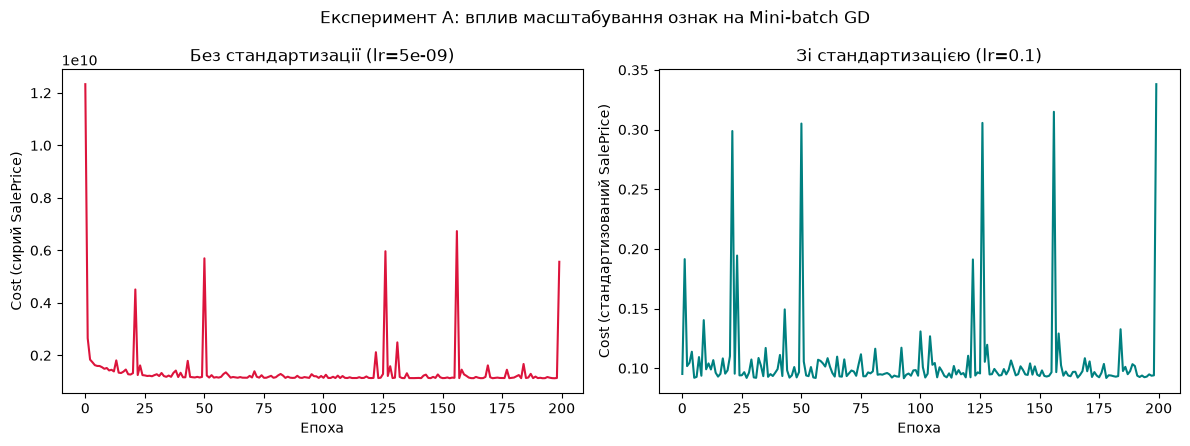

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(h_un, color='crimson')
axes[0].set_title(f'Без стандартизації (lr={lr_unscaled:.0e})')
axes[0].set_xlabel('Епоха'); axes[0].set_ylabel('Cost (сирий SalePrice)')
axes[1].plot(h_sc, color='teal')
axes[1].set_title(f'Зі стандартизацією (lr={lr_scaled})')
axes[1].set_xlabel('Епоха'); axes[1].set_ylabel('Cost (стандартизований SalePrice)')
plt.suptitle('Експеримент А: вплив масштабування ознак на Mini-batch GD')
plt.tight_layout(); plt.show()

**Результати й геометричне пояснення:**

Без стандартизації ознаки мають надзвичайно різні масштаби (наприклад, `Lot Area` —
тисячі-десятки тисяч, а `Overall Qual` — одиниці від 1 до 10). Через це навіть відносно
"великий" `lr = 1e-6` призводить до **розходження** (Cost вибухає до значень порядку
10¹³² вже за кілька епох), і працездатним виявляється лише надзвичайно малий
`lr ≈ 5·10⁻⁹`, який дає посередній результат ($R^2 \approx 0.56$–$0.63$) навіть за
200 епох. Зі стандартизацією ж усі ознаки мають порівнянний масштаб (середнє 0,
std 1), і той самий алгоритм із набагато більшим `lr = 0.1` **стабільно збігається** до
істотно кращого результату ($R^2 \approx 0.77$–$0.81$) за ту саму кількість епох.

Геометрично Cost Function лінійної регресії — це квадратична (параболоїдна) поверхня у
просторі ваг. Коли ознаки мають дуже різні масштаби, лінії рівня цієї поверхні є
**сильно витягнутими еліпсами** (вузька "вибалка" вздовж напрямку ознак із малим
масштабом і дуже пологий схил уздовж напрямку ознак із великим масштабом). Градієнтний
спуск рухається перпендикулярно до ліній рівня, тому в такому "яру" він змушений робити
криві, "зигзагоподібні" кроки — великий крок уздовж пологого напрямку легко "перестрибує"
дно яру в іншому, крутому напрямку, спричиняючи розходження. Стандартизація робить лінії
рівня близькими до кіл, тому градієнт майже завжди вказує прямо на мінімум, що дозволяє
використовувати значно більший і при цьому стабільний Learning Rate.

## Загальний висновок

У роботі реалізовано лінійну регресію "з нуля" на numpy (без використання
`sklearn.linear_model`) разом із трьома варіантами градієнтного спуску (Batch, SGD,
Mini-batch), проведено відбір ознак і коректну (без Data Leakage) попередню обробку
даних Ames Housing / House Prices. Найкращу та найстабільнішу якість показав Batch GD
($R^2_{test} \approx 0.87$), а аналіз залишків показав, що модель добре відтворює
лінійність у типовому ціновому діапазоні, проте порушує припущення нормальності та
гомоскедастичності помилок, тоді як мультиколінеарність серед фінальних ознак відсутня.
Експеримент з масштабуванням наочно продемонстрував, що стандартизація ознак є
критично важливою передумовою для стабільної та швидкої роботи градієнтного спуску.